# DS605: Fundamentals of Machine Learning
## Lab Assignment 7: Image Representation, PCA, Eigenfaces and Face Recognition

### Objective
The objective of this experiment is to represent face images as numerical feature vectors, reduce their dimensionality using Principal Component Analysis (PCA), visualize eigenfaces, reconstruct images, and compare face recognition methods.

### Dataset
The AT&T Database of Faces (ORL) is used in this experiment. It contains 400 grayscale face images belonging to 40 subjects, with 10 images per subject.

### Part A: Image Representation
In this section, the images are loaded as grayscale pixel matrices. Their dimensions and pixel intensity values are inspected. Each image is then flattened into a one-dimensional feature vector, and all images are combined into a feature matrix with corresponding subject labels.

### Important Note
PCA will be implemented using NumPy linear algebra operations. Scikit-learn will only be used for the traditional machine-learning comparison.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Set the dataset directory
DATA_DIR = Path("data")

# Check that the dataset directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        "The data folder was not found. "
        "Make sure the notebook is saved in the project folder."
    )

# Find and sort subject folders: s1, s2, ..., s40
subject_dirs = sorted(
    [
        folder for folder in DATA_DIR.iterdir()
        if folder.is_dir()
        and folder.name.startswith("s")
        and folder.name[1:].isdigit()
    ],
    key=lambda folder: int(folder.name[1:])
)

images = []
labels = []
image_paths = []

# Read every image as grayscale
for subject_dir in subject_dirs:
    subject_label = int(subject_dir.name[1:])

    subject_images = sorted(
        subject_dir.glob("*.pgm"),
        key=lambda path: int(path.stem)
    )

    for image_path in subject_images:
        with Image.open(image_path) as img:
            grayscale_image = np.array(
                img.convert("L"),
                dtype=np.uint8
            )

        images.append(grayscale_image)
        labels.append(subject_label)
        image_paths.append(image_path)

# Convert the lists into NumPy arrays
images = np.array(images, dtype=np.uint8)
y = np.array(labels, dtype=np.int64)

# Flatten each image into a one-dimensional feature vector
X = images.reshape(images.shape[0], -1).astype(np.float64)

# Display basic dataset information
print("Number of subjects:", len(subject_dirs))
print("Number of images:", len(images))
print("Image dimensions:", images[0].shape)
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Pixel intensity range:", images.min(), "to", images.max())
print("Unique subject labels:", np.unique(y))

Matplotlib is building the font cache; this may take a moment.


Number of subjects: 40
Number of images: 400
Image dimensions: (112, 92)
Feature matrix shape: (400, 10304)
Label array shape: (400,)
Pixel intensity range: 0 to 251
Unique subject labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]


### 2. Visual Inspection of Face Images

Each ORL image is represented as a two-dimensional grayscale matrix of size 112 × 92 pixels. Each pixel contains an intensity value, where 0 represents black and 255 represents white.

Visualizing the images helps us understand the variations in facial appearance, lighting, and expression. A histogram of pixel intensities shows how grayscale values are distributed across the dataset.

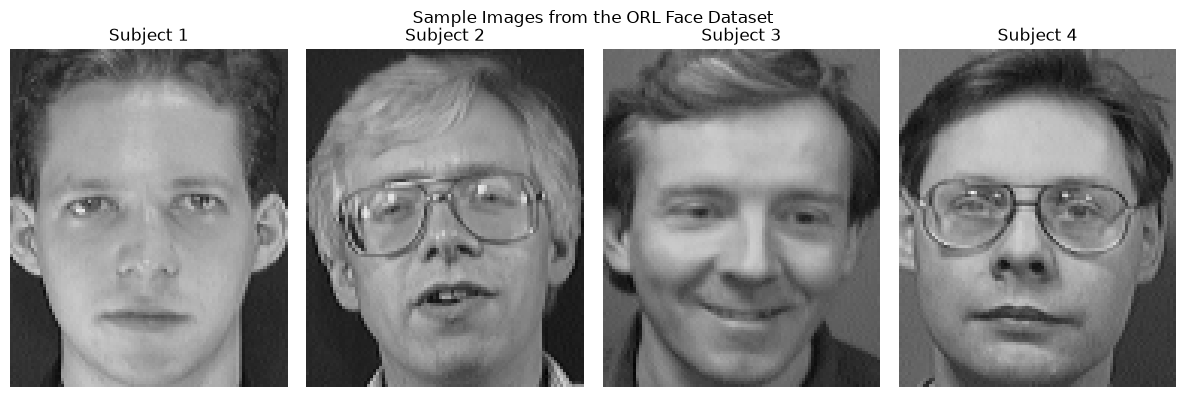

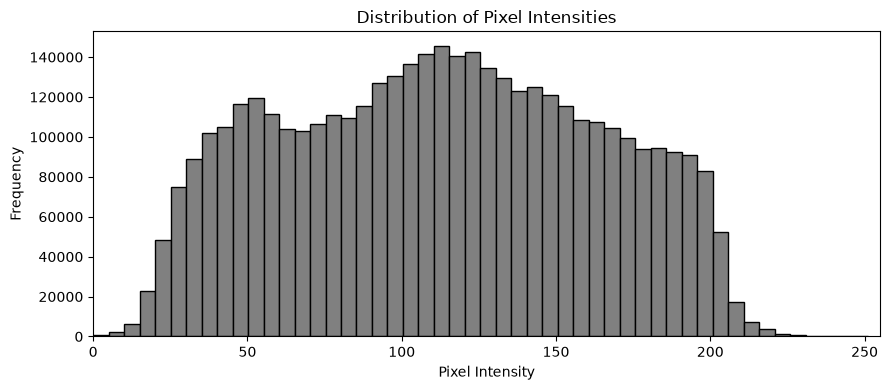

In [2]:
# Display sample face images from different subjects
sample_indices = [0, 10, 20, 30]

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for ax, idx in zip(axes, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Subject {y[idx]}")
    ax.axis("off")

plt.suptitle("Sample Images from the ORL Face Dataset")
plt.tight_layout()
plt.show()

# Plot the distribution of pixel intensities
plt.figure(figsize=(9, 4))
plt.hist(images.ravel(), bins=50, color="gray", edgecolor="black")
plt.title("Distribution of Pixel Intensities")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.tight_layout()

plt.savefig("figures/pixel_intensity_distribution.png", dpi=150)
plt.show()

### 3. Reproducible Train-Test Split

The dataset contains 10 images for each of the 40 subjects. To evaluate face recognition fairly, we split the images of each subject separately.

Seven images from every subject are assigned to the training set, and the remaining three images are assigned to the test set. Therefore, the training set contains 280 images and the test set contains 120 images.

A fixed random seed is used to make the split reproducible. This ensures that the same training and testing images are selected whenever the notebook is executed with the same dataset.

In [3]:
# Reproducible train-test split using NumPy only
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

train_indices = []
test_indices = []

# Split each subject separately
for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0].copy()

    # Randomly shuffle the image indices for this subject
    rng.shuffle(subject_indices)

    # 7 images for training, 3 for testing
    train_indices.extend(subject_indices[:7])
    test_indices.extend(subject_indices[7:])

# Shuffle the combined training and testing indices
train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

rng.shuffle(train_indices)
rng.shuffle(test_indices)

# Create training and testing datasets
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# Keep the original images for visualization later
images_train = images[train_indices]
images_test = images[test_indices]

# Display dataset sizes
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Verify that every subject is represented in both sets
print("Subjects in training set:", len(np.unique(y_train)))
print("Subjects in testing set:", len(np.unique(y_test)))

# Verify the number of images for each subject
print(
    "Training images per subject:",
    np.unique(y_train, return_counts=True)[1]
)

print(
    "Testing images per subject:",
    np.unique(y_test, return_counts=True)[1]
)

assert X_train.shape == (280, 10304)
assert X_test.shape == (120, 10304)
assert len(np.unique(y_train)) == 40
assert len(np.unique(y_test)) == 40

print("\nTrain-test split verified successfully!")

Training feature matrix: (280, 10304)
Testing feature matrix: (120, 10304)
Training labels: (280,)
Testing labels: (120,)
Subjects in training set: 40
Subjects in testing set: 40
Training images per subject: [7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7
 7 7 7]
Testing images per subject: [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3]

Train-test split verified successfully!


## Part B: PCA, Eigenfaces and Image Compression

### 4. Mean Face and Mean Centering

Principal Component Analysis (PCA) reduces the dimensionality of data by identifying directions that capture the greatest variation.

First, the mean face is calculated by averaging the pixel intensities of all training images. The mean face represents the average appearance across the training dataset.

Mean centering is then performed by subtracting the mean face from every training image vector. This ensures that PCA captures variation around the average face rather than the overall pixel intensity.

The mean face and centered training matrix are calculated using only the training data to prevent information leakage from the test set.

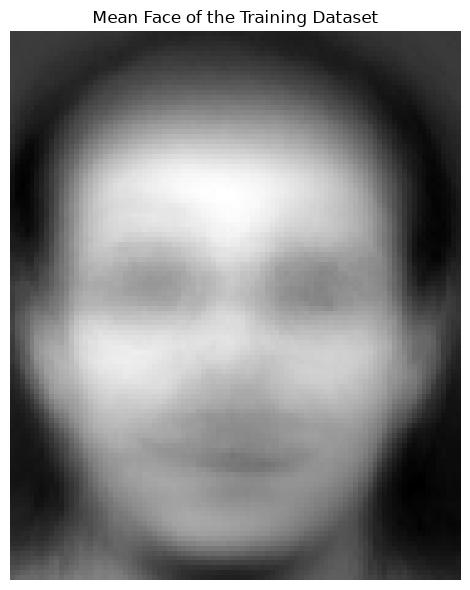

Mean face vector shape: (10304,)
Centered training matrix: (280, 10304)
Centered testing matrix: (120, 10304)
Mean of centered training data: 0.0


In [4]:
# Calculate the mean face using training data only
mean_face = np.mean(X_train, axis=0)

# Center the training and test data using the training mean
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Reshape the mean face into its original image dimensions
mean_face_image = mean_face.reshape(images.shape[1], images.shape[2])

# Display the mean face
plt.figure(figsize=(5, 6))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face of the Training Dataset")
plt.axis("off")
plt.tight_layout()
plt.savefig("figures/mean_face.png", dpi=150, bbox_inches="tight")
plt.show()

# Verify the dimensions
print("Mean face vector shape:", mean_face.shape)
print("Centered training matrix:", X_train_centered.shape)
print("Centered testing matrix:", X_test_centered.shape)

print(
    "Mean of centered training data:",
    round(float(np.mean(X_train_centered)), 6)
)

### 5. PCA Using Covariance and Eigendecomposition

PCA identifies directions in the data that capture the greatest variance. These directions are called principal components.

The covariance matrix describes how features vary together. However, directly constructing the pixel covariance matrix would require a matrix of size 10304 × 10304.

To reduce computation, we use the equivalent Gram matrix:

G = Xc Xcᵀ / (n - 1)

where Xc is the centered training matrix and n is the number of training images.

We calculate the eigenvalues and eigenvectors of this smaller matrix using NumPy. The eigenvectors are then mapped back to the original pixel-feature space to obtain the principal directions.

### 6. PCA Using Singular Value Decomposition (SVD)

SVD factorizes the centered training matrix as:

Xc = U S Vᵀ

Here, U contains the left singular vectors, S contains the singular values, and Vᵀ contains the principal directions in pixel space.

The variance associated with each principal component is calculated as:

Variance = singular value² / (n - 1)

We compare the eigenvalues and principal directions obtained using eigendecomposition and SVD. Both methods should produce equivalent principal directions, allowing for numerical precision and possible sign differences.

In [5]:
# ==========================================
# PCA METHOD 1: EIGENDECOMPOSITION
# ==========================================

n_train = X_train_centered.shape[0]

# Calculate the smaller Gram covariance matrix
gram_matrix = (
    X_train_centered @ X_train_centered.T
) / (n_train - 1)

print("Gram matrix shape:", gram_matrix.shape)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(gram_matrix)

# Sort in descending order of eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove tiny negative eigenvalues caused by numerical precision
eigenvalues = np.clip(eigenvalues, 0, None)

# Keep only numerically meaningful eigenvalues
valid = eigenvalues > eigenvalues[0] * 1e-12

eigenvalues_valid = eigenvalues[valid]
eigenvectors_valid = eigenvectors[:, valid]

# Map eigenvectors into the original pixel-feature space
components_eig = (
    X_train_centered.T @ eigenvectors_valid
) / np.sqrt(
    (n_train - 1) * eigenvalues_valid
)[None, :]

# Normalize the principal directions
components_eig /= np.linalg.norm(
    components_eig, axis=0, keepdims=True
)

print("Valid eigenvalues:", len(eigenvalues_valid))
print("Eigen-based component matrix:", components_eig.shape)


# ==========================================
# PCA METHOD 2: SINGULAR VALUE DECOMPOSITION
# ==========================================

U_svd, singular_values_svd, Vt_svd = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Variance explained by each SVD component
explained_variance_svd = (
    singular_values_svd ** 2
) / (n_train - 1)

# Explained variance ratio
explained_variance_ratio = (
    explained_variance_svd / explained_variance_svd.sum()
)

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Principal directions from SVD
components_svd = Vt_svd

print("\nSVD left singular vectors:", U_svd.shape)
print("SVD singular values:", singular_values_svd.shape)
print("SVD principal directions:", components_svd.shape)


# ==========================================
# COMPARE BOTH METHODS
# ==========================================

n_compare = min(
    10,
    components_eig.shape[1],
    components_svd.shape[0]
)

# Compare the corresponding leading eigenvalues and SVD variances
eigen_variance = eigenvalues_valid[:n_compare]
svd_variance = explained_variance_svd[:n_compare]

relative_errors = (
    np.abs(eigen_variance - svd_variance)
    / np.maximum(svd_variance, 1e-12)
)

# Compare principal directions using absolute cosine similarity.
# Absolute values account for sign differences in eigenvectors.
cosine_similarities = np.abs(
    np.sum(
        components_eig[:, :n_compare]
        * components_svd[:n_compare, :].T,
        axis=0
    )
)

print("\n--- PCA Method Comparison ---")
print("Components compared:", n_compare)
print(
    "Maximum relative eigenvalue error:",
    f"{relative_errors.max():.8f}"
)
print(
    "Mean absolute direction cosine similarity:",
    f"{cosine_similarities.mean():.6f}"
)

print("\nFirst 5 SVD explained variance ratios:")
print(np.round(explained_variance_ratio[:5], 5))

print("\nPCA methods completed successfully.")

Gram matrix shape: (280, 280)
Valid eigenvalues: 279
Eigen-based component matrix: (10304, 279)

SVD left singular vectors: (280, 280)
SVD singular values: (280,)
SVD principal directions: (280, 10304)

--- PCA Method Comparison ---
Components compared: 10
Maximum relative eigenvalue error: 0.00000000
Mean absolute direction cosine similarity: 1.000000

First 5 SVD explained variance ratios:
[0.17757 0.12584 0.07073 0.05722 0.05082]

PCA methods completed successfully.


### 7. Explained Variance and Component Selection

Each principal component captures a portion of the variation present in the training images. The explained variance ratio measures the proportion of total variance captured by a component.

The cumulative explained variance is obtained by adding the explained variance ratios of successive components.

In this experiment, we select the minimum number of principal components required to preserve at least 90% of the training-data variance. This reduces the number of features while retaining most of the information represented by the original pixel data.

The cumulative explained variance curve is plotted to visualize the relationship between the number of components and the information retained.

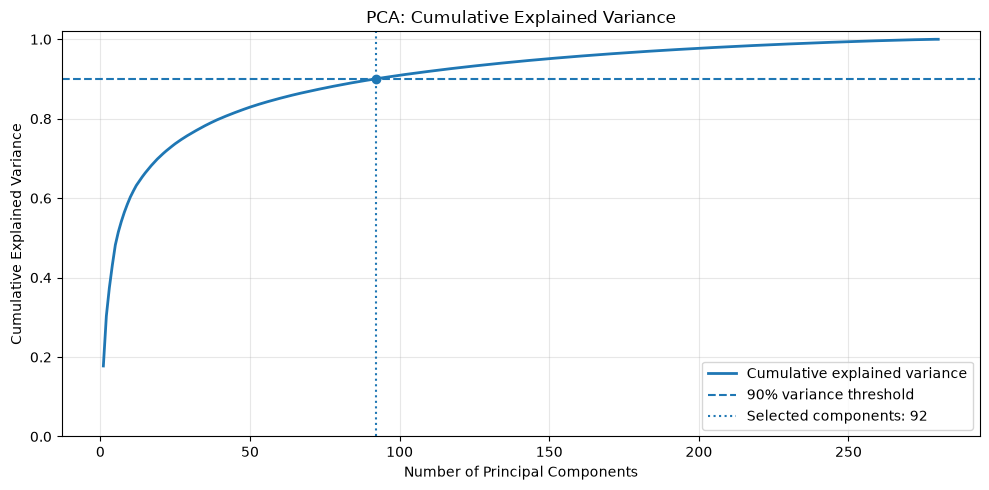

Minimum components for at least 90% variance: 92
Variance retained: 90.0366%


In [6]:
# Ensure the output directory exists
Path("figures").mkdir(exist_ok=True)

# Find the minimum number of components needed for at least 90% variance
n_components_90 = int(
    np.searchsorted(cumulative_variance, 0.90) + 1
)

variance_retained_90 = cumulative_variance[n_components_90 - 1]

# Plot cumulative explained variance
component_numbers = np.arange(1, len(cumulative_variance) + 1)

plt.figure(figsize=(10, 5))
plt.plot(
    component_numbers,
    cumulative_variance,
    linewidth=2,
    label="Cumulative explained variance"
)
plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance threshold"
)
plt.axvline(
    x=n_components_90,
    linestyle=":",
    label=f"Selected components: {n_components_90}"
)
plt.scatter(
    n_components_90,
    variance_retained_90,
    zorder=3
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/explained_variance.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Minimum components for at least 90% variance:", n_components_90)
print(f"Variance retained: {variance_retained_90:.4%}")

### 8. Eigenface Visualization

Eigenfaces are obtained by reshaping the principal directions learned by PCA into the original image dimensions.

Each eigenface describes a pattern of variation across facial images. Components with larger eigenvalues represent directions containing more variance in the training dataset.

We visualize the first 16 eigenfaces using a diverging color map. Positive and negative values represent opposite directions of pixel variation relative to the mean face.

The selected principal components will later be used to project the training and test images into a lower-dimensional representation.

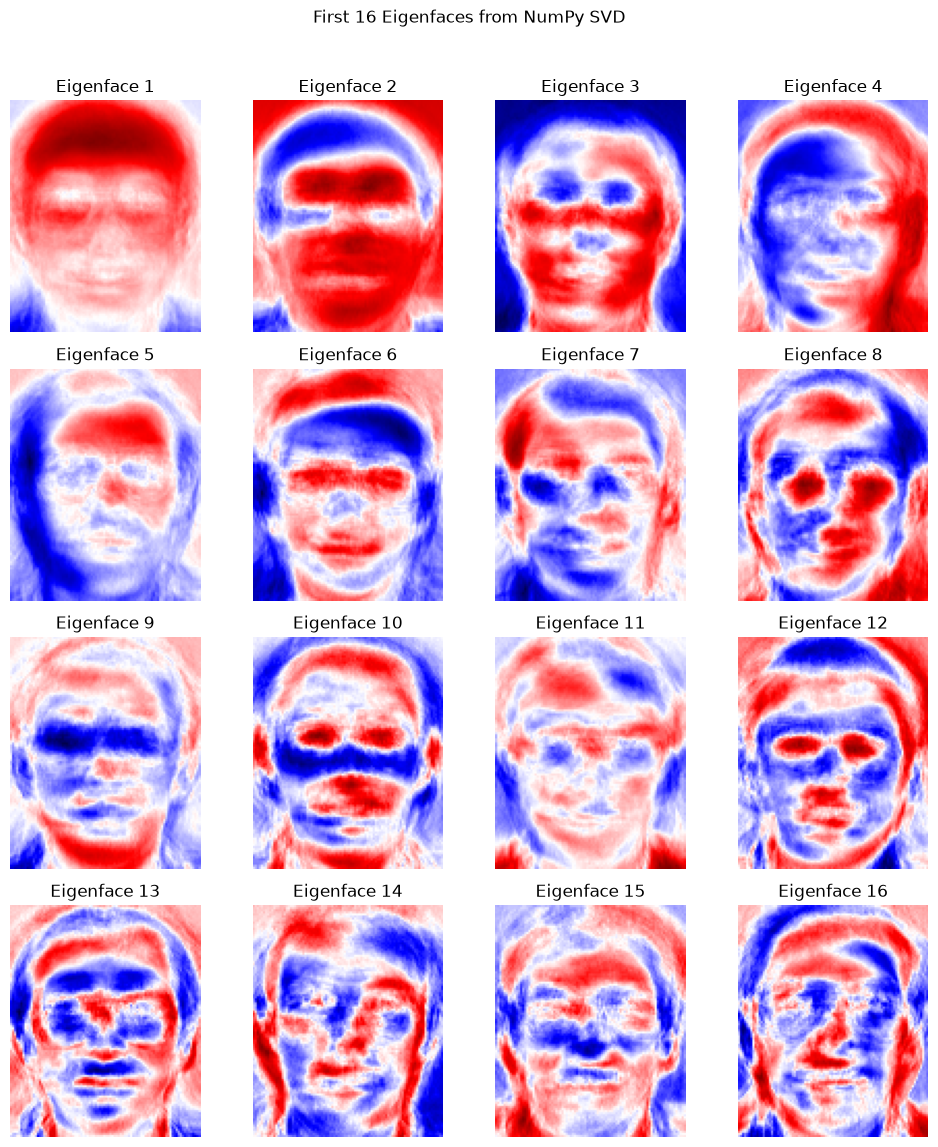

Selected PCA components: (92, 10304)
Explained-variance figure saved to figures/explained_variance.png
Eigenface figure saved to figures/eigenfaces.png


In [7]:
# Select the PCA directions that preserve at least 90% variance
components_90 = components_svd[:n_components_90, :]

# Display the first 16 eigenfaces
n_show = min(16, components_90.shape[0])
n_cols = 4
n_rows = int(np.ceil(n_show / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(10, 2.8 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i in range(n_show):
    eigenface = components_90[i].reshape(images.shape[1:])

    # Use symmetric scaling to show positive and negative variations
    limit = np.max(np.abs(eigenface))

    axes[i].imshow(
        eigenface,
        cmap="seismic",
        vmin=-limit,
        vmax=limit
    )
    axes[i].set_title(f"Eigenface {i + 1}")
    axes[i].axis("off")

# Hide any unused subplot axes
for i in range(n_show, len(axes)):
    axes[i].axis("off")

plt.suptitle("First 16 Eigenfaces from NumPy SVD", y=1.02)
plt.tight_layout()

plt.savefig(
    "figures/eigenfaces.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Selected PCA components:", components_90.shape)
print("Explained-variance figure saved to figures/explained_variance.png")
print("Eigenface figure saved to figures/eigenfaces.png")

### 9. PCA Projection and Image Reconstruction

After selecting the principal components, each centered face image is projected into PCA space. The resulting PCA coefficients form a compact numerical representation of the image.

The projection is calculated by multiplying the centered image vector by the selected principal directions. To reconstruct an image, the PCA coefficients are multiplied by the same principal directions, and the mean face is added back.

Reconstruction quality is evaluated by comparing the original and reconstructed images using Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR). Lower MSE and higher PSNR generally indicate better reconstruction quality.

### 10. Storage Comparison

The original representation stores 10,304 grayscale pixel values per image, whereas the reduced representation stores only 92 PCA coefficients per image.

We compare the memory required by the pixel data and PCA coefficients. We also account for the additional storage needed for the PCA basis and mean face, which are required to reconstruct images.

Training PCA representation: (280, 92)
Testing PCA representation: (120, 92)


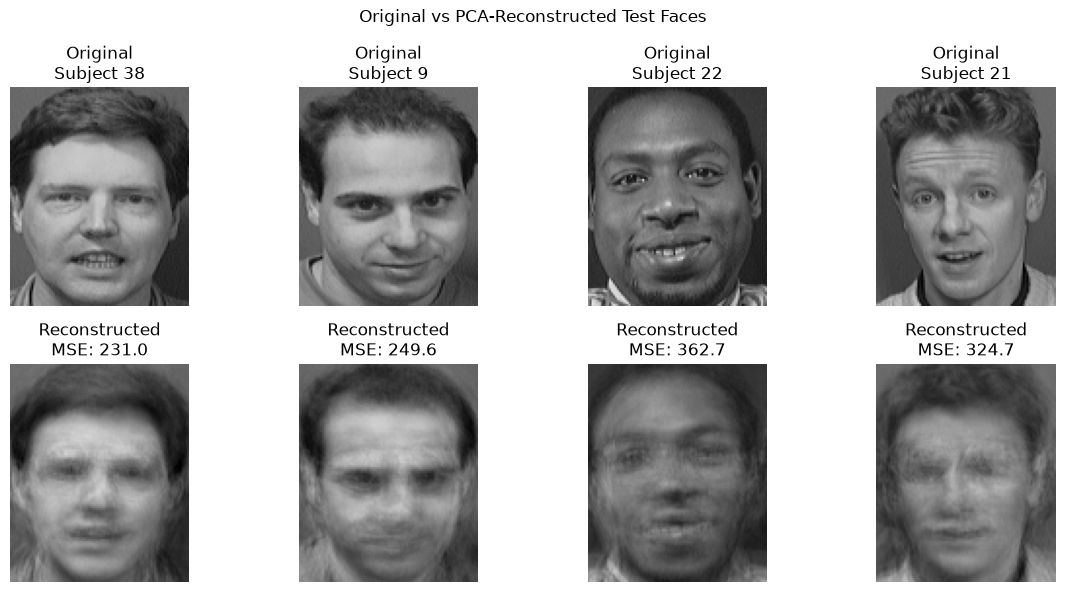

Mean test reconstruction MSE: 335.5241
Mean test reconstruction PSNR: 22.87 dB

--- Storage Comparison ---
Original pixel payload per image: 10,304 bytes
PCA feature payload per image: 736 bytes
Per-image payload reduction: 92.86%
All original images in memory: 4,121,600 bytes
All PCA feature vectors: 294,400 bytes
PCA basis and mean face: 7,666,176 bytes
Features + basis + mean: 7,960,576 bytes

Reduced representations saved to results/pca_representations.npz
Reconstruction figure saved to figures/reconstruction.png


In [8]:
# Project training and test images into PCA space
X_train_pca = X_train_centered @ components_90.T
X_test_pca = X_test_centered @ components_90.T

print("Training PCA representation:", X_train_pca.shape)
print("Testing PCA representation:", X_test_pca.shape)

# Reconstruct training and test images
X_train_reconstructed = X_train_pca @ components_90 + mean_face
X_test_reconstructed = X_test_pca @ components_90 + mean_face

# Select four test images for visualization
sample_indices = [0, 1, 2, 3]

fig, axes = plt.subplots(2, len(sample_indices), figsize=(12, 6))

sample_mse = []
sample_psnr = []

for col, idx in enumerate(sample_indices):
    original = X_test[idx].reshape(images.shape[1:])
    reconstructed = X_test_reconstructed[idx].reshape(images.shape[1:])

    mse = np.mean((original - reconstructed) ** 2)
    psnr = 10 * np.log10(255**2 / mse) if mse > 0 else float("inf")

    sample_mse.append(mse)
    sample_psnr.append(psnr)

    axes[0, col].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"Original\nSubject {y_test[idx]}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        np.clip(reconstructed, 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, col].set_title(f"Reconstructed\nMSE: {mse:.1f}")
    axes[1, col].axis("off")

plt.suptitle("Original vs PCA-Reconstructed Test Faces")
plt.tight_layout()

plt.savefig(
    "figures/reconstruction.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Evaluate reconstruction on the complete test set
test_mse = np.mean((X_test - X_test_reconstructed) ** 2)
test_psnr = 10 * np.log10(255**2 / test_mse) if test_mse > 0 else float("inf")

print(f"Mean test reconstruction MSE: {test_mse:.4f}")
print(f"Mean test reconstruction PSNR: {test_psnr:.2f} dB")

# Compare feature payload storage
original_bytes_per_image = images.shape[1] * images.shape[2] * np.dtype(np.uint8).itemsize
pca_bytes_per_image = n_components_90 * np.dtype(np.float64).itemsize

original_dataset_bytes = images.nbytes
all_pca_features = np.vstack([X_train_pca, X_test_pca])
pca_feature_bytes = all_pca_features.nbytes

basis_bytes = components_90.nbytes + mean_face.nbytes
total_pca_bytes = pca_feature_bytes + basis_bytes

print("\n--- Storage Comparison ---")
print(f"Original pixel payload per image: {original_bytes_per_image:,} bytes")
print(f"PCA feature payload per image: {pca_bytes_per_image:,} bytes")
print(f"Per-image payload reduction: {100 * (1 - pca_bytes_per_image / original_bytes_per_image):.2f}%")
print(f"All original images in memory: {original_dataset_bytes:,} bytes")
print(f"All PCA feature vectors: {pca_feature_bytes:,} bytes")
print(f"PCA basis and mean face: {basis_bytes:,} bytes")
print(f"Features + basis + mean: {total_pca_bytes:,} bytes")

# Store reduced representations and labels
np.savez_compressed(
    "results/pca_representations.npz",
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
    y_train=y_train,
    y_test=y_test,
    mean_face=mean_face,
    components=components_90
)

print("\nReduced representations saved to results/pca_representations.npz")
print("Reconstruction figure saved to figures/reconstruction.png")

## Part C: Face Recognition in PCA Space

### 11. Similarity-Based Face Recognition

In this section, each test image is matched to the most similar training image. Similarity is measured using Euclidean distance.

For each test image, we calculate its distance from all training images and select the training image with the smallest distance. The predicted subject label is the label of that nearest training image.

We perform this experiment twice:
1. Using the original pixel feature vectors.
2. Using the reduced PCA representations containing 92 coefficients.

Recognition accuracy is calculated as the percentage of test images whose predicted subject labels match their true labels. Both approaches use the same training and testing images, allowing a fair comparison.

In [9]:
# Calculate squared Euclidean distances efficiently
def nearest_neighbor_indices(X_reference, X_query):
    """
    Return the closest reference sample for every query sample,
    using Euclidean distance and NumPy operations.
    """
    reference_squared_norms = np.sum(
        X_reference ** 2, axis=1
    )

    query_squared_norms = np.sum(
        X_query ** 2, axis=1, keepdims=True
    )

    squared_distances = (
        query_squared_norms
        + reference_squared_norms[None, :]
        - 2 * (X_query @ X_reference.T)
    )

    # Prevent tiny negative values from numerical precision
    squared_distances = np.maximum(squared_distances, 0)

    # Find the closest training image for each test image
    nearest_indices = np.argmin(squared_distances, axis=1)

    nearest_distances = np.sqrt(
        squared_distances[
            np.arange(len(X_query)),
            nearest_indices
        ]
    )

    return nearest_indices, nearest_distances


# ------------------------------------------
# Recognition using raw pixel features
# ------------------------------------------

raw_nearest_indices, raw_distances = nearest_neighbor_indices(
    X_train,
    X_test
)

y_pred_raw = y_train[raw_nearest_indices]


# ------------------------------------------
# Recognition using PCA features
# ------------------------------------------

pca_nearest_indices, pca_distances = nearest_neighbor_indices(
    X_train_pca,
    X_test_pca
)

y_pred_pca = y_train[pca_nearest_indices]


# ------------------------------------------
# Calculate recognition accuracy
# ------------------------------------------

raw_accuracy = np.mean(y_pred_raw == y_test)
pca_accuracy = np.mean(y_pred_pca == y_test)

print("--- Nearest-Neighbor Recognition Results ---")
print(f"Raw-pixel accuracy: {raw_accuracy:.4f} ({raw_accuracy * 100:.2f}%)")
print(f"PCA-space accuracy: {pca_accuracy:.4f} ({pca_accuracy * 100:.2f}%)")

print("\nCorrect raw-pixel predictions:", np.sum(y_pred_raw == y_test), "out of", len(y_test))
print("Correct PCA predictions:", np.sum(y_pred_pca == y_test), "out of", len(y_test))


# ------------------------------------------
# Save per-image recognition results
# ------------------------------------------

recognition_results = pd.DataFrame({
    "test_image": [str(image_paths[i]) for i in test_indices],
    "true_subject": y_test,
    "raw_predicted_subject": y_pred_raw,
    "raw_distance": raw_distances,
    "raw_correct": y_pred_raw == y_test,
    "pca_predicted_subject": y_pred_pca,
    "pca_distance": pca_distances,
    "pca_correct": y_pred_pca == y_test
})

recognition_results.to_csv(
    "results/recognition_results.csv",
    index=False
)

# Create an overall comparison table
recognition_comparison = pd.DataFrame({
    "Method": ["Raw-pixel nearest neighbor", "PCA nearest neighbor"],
    "Features per image": [X_train.shape[1], X_train_pca.shape[1]],
    "Correct predictions": [
        int(np.sum(y_pred_raw == y_test)),
        int(np.sum(y_pred_pca == y_test))
    ],
    "Test images": [len(y_test), len(y_test)],
    "Accuracy (%)": [
        raw_accuracy * 100,
        pca_accuracy * 100
    ]
})

display(recognition_comparison.round(2))

recognition_comparison.to_csv(
    "results/nearest_neighbor_comparison.csv",
    index=False
)

print("\nSaved results/recognition_results.csv")
print("Saved results/nearest_neighbor_comparison.csv")

--- Nearest-Neighbor Recognition Results ---
Raw-pixel accuracy: 0.9750 (97.50%)
PCA-space accuracy: 0.9750 (97.50%)

Correct raw-pixel predictions: 117 out of 120
Correct PCA predictions: 117 out of 120


,Method,Features per image,Correct predictions,Test images,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,117,120,97.5
1,PCA nearest neighbor,92,117,120,97.5



Saved results/recognition_results.csv
Saved results/nearest_neighbor_comparison.csv


### 12. Inspection of Correct and Incorrect Matches

Numerical accuracy indicates the overall performance of a recognition method, but inspecting individual predictions helps explain its behavior.

For selected test images, we display the query face alongside its nearest training face in PCA space. We compare the true subject label with the predicted subject label to identify correct and incorrect matches.

This inspection helps reveal whether visually similar faces, lighting differences, or changes in facial expression may contribute to recognition errors.

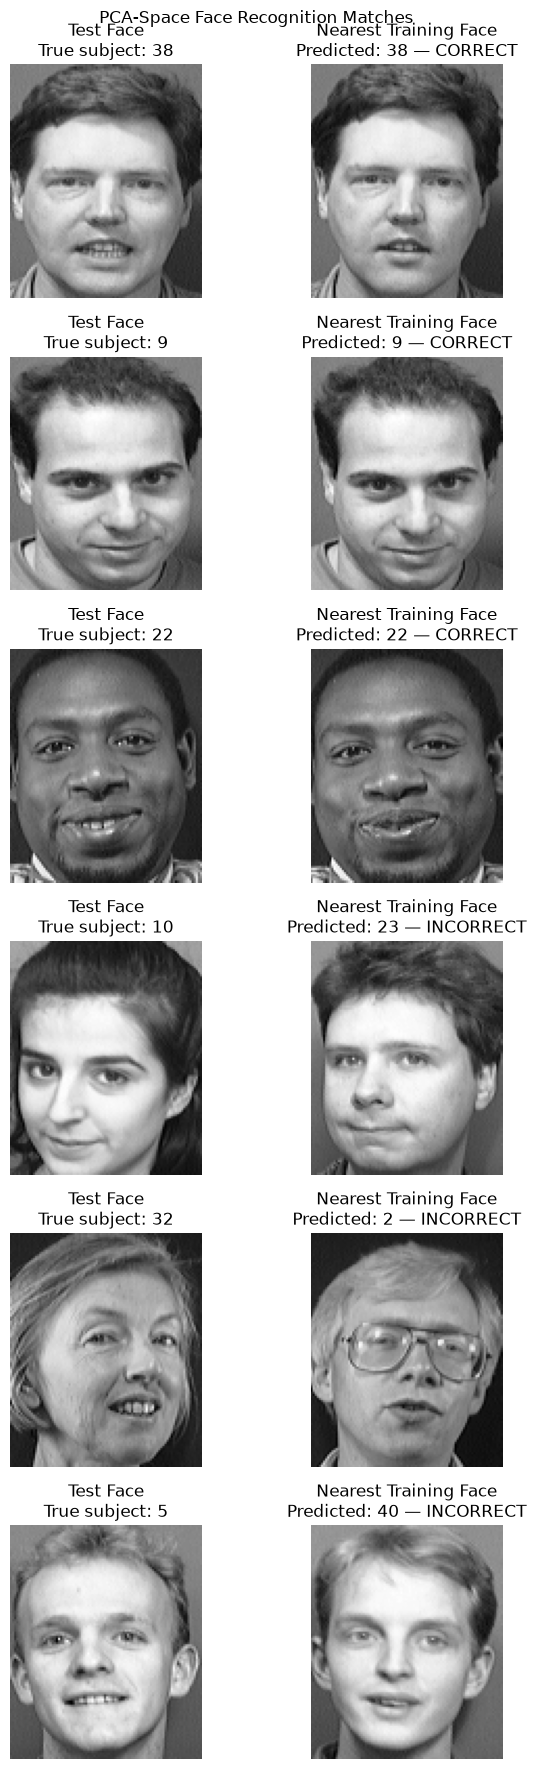

Correct PCA matches available: 117
Incorrect PCA matches available: 3
Recognition figure saved to figures/recognition_matches.png


In [10]:
# Find correct and incorrect PCA predictions
correct_indices = np.where(y_pred_pca == y_test)[0]
incorrect_indices = np.where(y_pred_pca != y_test)[0]

# Select up to three examples from each category
selected_correct = correct_indices[:3]
selected_incorrect = incorrect_indices[:3]

selected_test_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

if len(selected_test_indices) == 0:
    print("No test examples were available for visualization.")
else:
    n_examples = len(selected_test_indices)

    fig, axes = plt.subplots(
        n_examples,
        2,
        figsize=(7, 3 * n_examples),
        squeeze=False
    )

    for row, test_idx in enumerate(selected_test_indices):
        nearest_train_idx = pca_nearest_indices[test_idx]

        query_image = images_test[test_idx]
        matched_image = images_train[nearest_train_idx]

        true_subject = y_test[test_idx]
        predicted_subject = y_pred_pca[test_idx]

        is_correct = true_subject == predicted_subject
        result_label = "CORRECT" if is_correct else "INCORRECT"

        axes[row, 0].imshow(query_image, cmap="gray")
        axes[row, 0].set_title(
            f"Test Face\nTrue subject: {true_subject}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(matched_image, cmap="gray")
        axes[row, 1].set_title(
            f"Nearest Training Face\n"
            f"Predicted: {predicted_subject} — {result_label}"
        )
        axes[row, 1].axis("off")

    plt.suptitle("PCA-Space Face Recognition Matches")
    plt.tight_layout()

    plt.savefig(
        "figures/recognition_matches.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

print("Correct PCA matches available:", len(correct_indices))
print("Incorrect PCA matches available:", len(incorrect_indices))
print("Recognition figure saved to figures/recognition_matches.png")

## Part D: Traditional Machine-Learning Classifiers

### 13. Classification Using PCA Features

The PCA coefficients provide a reduced representation of each face image. In this section, traditional machine-learning classifiers are trained using these features to predict the subject identity.

Three classifiers are evaluated:

1. K-Nearest Neighbors (KNN): predicts the subject based on the labels of nearby training samples.
2. Logistic Regression: learns a classification model that estimates the probability of each subject class.
3. Support Vector Machine (SVM): learns decision boundaries that separate different subject classes.

The classifiers use PCA features obtained from the NumPy implementation of SVD. A StandardScaler is included inside each classification pipeline so that scaling parameters are fitted using training data only.

The performance of these classifiers is compared with the NumPy-based nearest-neighbor baseline. Recognition accuracy is measured on the same held-out test set.

,Components,Variance retained (%),Method,Accuracy (%)
0,20,70.55,PCA 1-NN baseline,95.00
1,20,70.55,SVM (RBF),93.33
2,20,70.55,Logistic Regression,90.83
3,20,70.55,KNN (k=3),88.33
4,40,80.04,PCA 1-NN baseline,97.50
5,40,80.04,Logistic Regression,95.83
6,40,80.04,SVM (RBF),95.83
7,40,80.04,KNN (k=3),90.00
8,60,85.14,PCA 1-NN baseline,97.50
9,60,85.14,SVM (RBF),95.83



--- Accuracy at 90% Variance ---


,Components,Variance retained (%),Method,Accuracy (%)
0,92,90.04,PCA 1-NN baseline,97.50
1,92,90.04,Logistic Regression,95.00
2,92,90.04,SVM (RBF),93.33
3,92,90.04,KNN (k=3),75.00



Results saved to results/model_comparison.csv


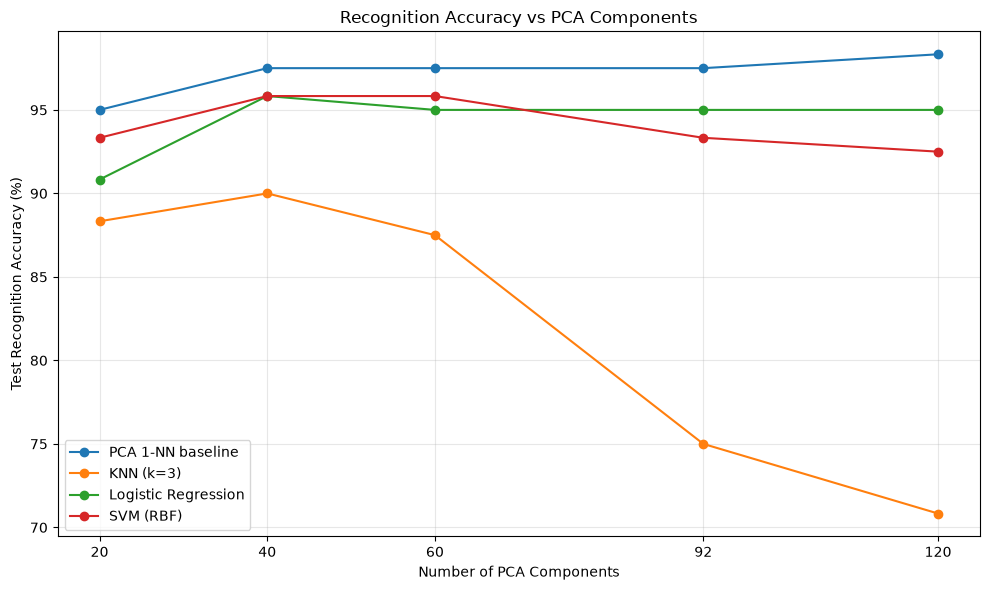

Comparison plot saved to figures/model_comparison.png


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Experiment with different numbers of PCA components
component_candidates = sorted(set([
    20,
    40,
    60,
    n_components_90,
    120
]))

component_candidates = [
    k for k in component_candidates
    if 1 <= k <= components_svd.shape[0]
]

# Define the traditional ML classifiers
classifier_templates = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale")
}

comparison_records = []
predictions_at_92 = {}

# Experiment with each component count
for k in component_candidates:

    # Obtain the first k NumPy-computed PCA directions
    components_k = components_svd[:k, :]

    # Project centered images into the selected PCA space
    X_train_k = X_train_centered @ components_k.T
    X_test_k = X_test_centered @ components_k.T

    # ------------------------------------------
    # NumPy nearest-neighbor baseline
    # ------------------------------------------
    nn_indices_k, _ = nearest_neighbor_indices(
        X_train_k,
        X_test_k
    )

    y_pred_nn_k = y_train[nn_indices_k]

    nn_accuracy_k = accuracy_score(
        y_test,
        y_pred_nn_k
    )

    comparison_records.append({
        "Components": k,
        "Variance retained (%)": (
            cumulative_variance[k - 1] * 100
        ),
        "Method": "PCA 1-NN baseline",
        "Accuracy (%)": nn_accuracy_k * 100
    })

    # ------------------------------------------
    # Traditional machine-learning classifiers
    # ------------------------------------------
    for model_name, model_template in classifier_templates.items():

        # Scaling is fitted only on the training data
        model = make_pipeline(
            StandardScaler(),
            model_template
        )

        model.fit(X_train_k, y_train)
        y_pred = model.predict(X_test_k)

        accuracy = accuracy_score(y_test, y_pred)

        comparison_records.append({
            "Components": k,
            "Variance retained (%)": (
                cumulative_variance[k - 1] * 100
            ),
            "Method": model_name,
            "Accuracy (%)": accuracy * 100
        })

        # Keep predictions for the 90%-variance model
        if k == n_components_90:
            predictions_at_92[model_name] = y_pred.copy()


# Include the raw-pixel nearest-neighbor baseline
comparison_records.append({
    "Components": X_train.shape[1],
    "Variance retained (%)": np.nan,
    "Method": "Raw-pixel 1-NN baseline",
    "Accuracy (%)": raw_accuracy * 100
})

# Create the comparison table
model_comparison = pd.DataFrame(comparison_records)

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy (%)"].round(2)
)

model_comparison["Variance retained (%)"] = (
    model_comparison["Variance retained (%)"].round(2)
)

display(
    model_comparison.sort_values(
        ["Components", "Accuracy (%)"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

# Save the complete comparison table
model_comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("\n--- Accuracy at 90% Variance ---")

selected_results = model_comparison[
    model_comparison["Components"] == n_components_90
].sort_values("Accuracy (%)", ascending=False)

display(selected_results.reset_index(drop=True))

print("\nResults saved to results/model_comparison.csv")


# ------------------------------------------
# Plot accuracy against component count
# ------------------------------------------

pca_results = model_comparison[
    model_comparison["Method"] != "Raw-pixel 1-NN baseline"
]

plt.figure(figsize=(10, 6))

for method in pca_results["Method"].unique():
    method_results = (
        pca_results[pca_results["Method"] == method]
        .sort_values("Components")
    )

    plt.plot(
        method_results["Components"],
        method_results["Accuracy (%)"],
        marker="o",
        label=method
    )

plt.xlabel("Number of PCA Components")
plt.ylabel("Test Recognition Accuracy (%)")
plt.title("Recognition Accuracy vs PCA Components")
plt.xticks(component_candidates)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Comparison plot saved to figures/model_comparison.png")